<a href="https://colab.research.google.com/github/naserhusovic-droid/DSB-Unit-03/blob/main/06%20-%20Model%20Workflow/02-model-workflow-live-classroom.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://github.com/naserhusovic-droid/DSB-Unit-03/blob/main/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Modeling Workflow (Walkthrough) - Solution

---

### About
Model data from scratch: gather data, clean it, explore it, and then evaluate several models.

### Learning Objectives
- Gather, clean, explore and model a dataset from scratch.
- Split data into testing and training sets using both train/test split and cross-validation and apply both techniques to score a model.
- Evaluate several models.


### Notebook Guide

- Importing libaries
- Load the Data
- Data Cleaning:
     - Initial check
     - Clean up PhD column
     - Drop `NaN`s
- Feature engineering: Binarize `Private` column
- EDA:
     - `apps`
     - What else do we want to explore?
     - Create Histograms of All Numerical Columns
     - Plot a Heatmap of the Correlation Matrix
     - Use seaborn's `.pairplot()` method to create scatterplots
- Model Prep:
     - Create our features matrix (`X`) and target vector (`y`)
     - Train/test split
     - Scaling
     - Instantiate our model
- Evaluation
- LINE Assumptions

# Importing libaries
---

We'll need the following libraries for today's lesson:

1. `pandas`
2. `numpy`
3. `seaborn`
4. `matplotlib.pyplot`
4. `train_test_split` and `cross_val_score` from `sklearn`'s `model_selection` module
5. `LinearRegression`, `LassoCV` and `RidgeCV` from `sklearn`'s `linear_model` module
6. `StandardScaler` from `sklearn`'s `preprocessing` module
7. `mean_squared_error` from `sklearn`'s `metrics` module

In [58]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load the Data

---

Today's [data set](http://www-bcf.usc.edu/~gareth/ISL/data.html) (`College.csv`) is from the [ISLR website](https://cran.r-project.org/web/packages/ISLR/ISLR.pdf) on page 5.

Rename `Unnamed: 0` to `University`.

In [59]:
df = pd.read_csv('https://raw.githubusercontent.com/naserhusovic-droid/DSB-Unit-03/refs/heads/main/data/College.csv')
df.rename(columns={'Unnamed: 0': 'University'}, inplace=True)
df.head()

,University,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


 Lowercase and snakecase all column names.

In [60]:
df.columns = df.columns.str.lower().str.replace('.', '_')
df.head()

,university,private,apps,accept,enroll,top10perc,top25perc,f_undergrad,p_undergrad,outstate,room_board,books,personal,phd,terminal,s_f_ratio,perc_alumni,expend,grad_rate
0,Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   university   777 non-null    object 
 1   private      777 non-null    object 
 2   apps         777 non-null    int64  
 3   accept       777 non-null    int64  
 4   enroll       777 non-null    int64  
 5   top10perc    777 non-null    int64  
 6   top25perc    777 non-null    int64  
 7   f_undergrad  777 non-null    int64  
 8   p_undergrad  777 non-null    int64  
 9   outstate     777 non-null    int64  
 10  room_board   777 non-null    int64  
 11  books        777 non-null    int64  
 12  personal     777 non-null    int64  
 13  phd          777 non-null    object 
 14  terminal     777 non-null    int64  
 15  s_f_ratio    777 non-null    float64
 16  perc_alumni  777 non-null    int64  
 17  expend       777 non-null    int64  
 18  grad_rate    777 non-null    int64  
dtypes: float

# Data cleaning: Initial check
---

Check the following in the cells below:
1. Do we have any null values?
2. Are any numerical columns being read in as `object`?

In [62]:
# Check for nulls
df.isnull().sum()

,0
university,0
private,0
apps,0
accept,0
enroll,0
top10perc,0
top25perc,0
f_undergrad,0
p_undergrad,0
outstate,0


In [63]:
# Check column data types
df.dtypes

,0
university,object
private,object
apps,int64
accept,int64
enroll,int64
top10perc,int64
top25perc,int64
f_undergrad,int64
p_undergrad,int64
outstate,int64


In [64]:
# Hmm... PHD

df['phd'].value_counts()

,count
phd,
?,29
77,26
73,24
90,22
71,21
...,...
32,1
14,1
103,1


# Data cleaning: Clean up `PhD` column
---

`PhD` is being read in as a string because some of the cells contain non-numerical values. In the cell below, replace any non-numerical values with `NaN`'s, and change the column datatype to float.

In [65]:
df['phd'] = df['phd'].replace('?', np.nan).astype(float)

#df['phd'] = df['phd'].map(lambda phd: np.nan if phd == '?' else float(phd))
#df['phd'] = np.where(df['phd'] == '?', np.nan, df['phd']).astype(float)
#df.loc[~df.phd.str.isdigit(), 'phd'] = np.nan


In [66]:
df.dtypes

,0
university,object
private,object
apps,int64
accept,int64
enroll,int64
top10perc,int64
top25perc,int64
f_undergrad,int64
p_undergrad,int64
outstate,int64


In [67]:
df.isnull().sum()

,0
university,0
private,0
apps,0
accept,0
enroll,0
top10perc,0
top25perc,0
f_undergrad,0
p_undergrad,0
outstate,0


# Data cleaning: Drop `NaN`s
---

Since there are a small percentage of null cells, let's go ahead and drop them.

In [68]:
df.shape

(777, 19)

In [69]:
df.dropna(inplace=True)

In [70]:
df.shape

(748, 19)

# Feature engineering: Binarize `Private` column
---

In the cells below, convert the `Private` column into numerical values.

In [71]:
df['private'].value_counts()

,count
private,
Yes,544
No,204


In [72]:
map_dic = {
    "Yes":1,
    "No": 0
}

In [73]:
df['private'] = df['private'].map({'Yes': 1, 'No': 0})
# df['private'] = df['private'].map({'Yes': 1, 'No': 0})
# df['private'] = df['private'].apply({'Yes': 1, 'No': 0})
# df['private'] = df['private'].map(lambda s: int(s == 'Yes'))
# df['private'] = np.where(df['private'] == 'Yes', 1, 0)

# EDA: `apps`

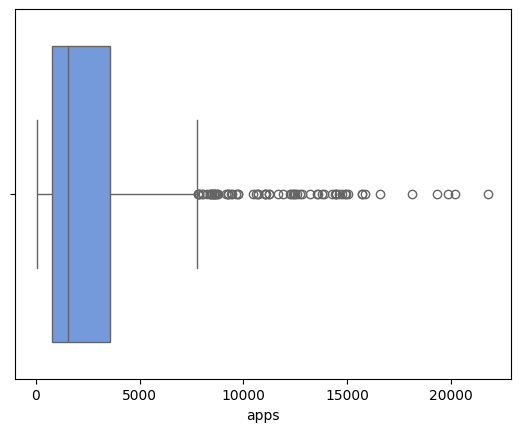

In [110]:
sns.boxplot(x = df['apps'], color = 'cornflowerblue');

In [75]:
df[df['apps'] > 30000]

,university,private,apps,accept,enroll,top10perc,top25perc,f_undergrad,p_undergrad,outstate,room_board,books,personal,phd,terminal,s_f_ratio,perc_alumni,expend,grad_rate
483,Rutgers at New Brunswick,0,48094,26330,4520,36,79,21401,3712,7410,4748,690,2009,90.0,95,19.5,19,10474,77


In [76]:
df.shape

(748, 19)

In [111]:
# We can make a decision to drop the outlier, if we want! Test it!

df_clean = df[df['apps'] < 30000]
df_clean.shape

(747, 19)

# EDA: What else do we want to explore?
---

In [78]:
df.describe()

,private,apps,accept,enroll,top10perc,top25perc,f_undergrad,p_undergrad,outstate,room_board,books,personal,phd,terminal,s_f_ratio,perc_alumni,expend,grad_rate
count,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000,747.000000
mean,0.728246,2910.666667,1968.243641,769.631861,27.465863,55.730924,3660.485944,852.986613,10418.489960,4359.144578,549.164659,1339.187416,72.495315,79.593039,14.067068,22.844712,9600.455154,65.404284
std,0.445162,3484.046511,2265.944031,916.220783,17.479206,19.662328,4820.034084,1535.697307,3991.571486,1099.936118,167.036513,679.595552,16.313563,14.628110,3.892019,12.352724,5129.324634,17.148379
min,0.000000,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,300.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.000000
25%,0.000000,760.000000,588.000000,239.000000,15.000000,41.000000,985.500000,95.000000,7254.000000,3594.500000,451.000000,850.000000,62.000000,70.500000,11.500000,13.000000,6754.000000,53.000000
50%,1.000000,1538.000000,1107.000000,432.000000,23.000000,54.000000,1704.000000,350.000000,9950.000000,4194.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8354.000000,65.000000
75%,1.000000,3575.000000,2367.000000,873.500000,35.000000,69.000000,3898.500000,963.500000,12869.000000,5066.000000,600.000000,1682.500000,85.000000,92.000000,16.400000,31.000000,10796.000000,78.000000
max,1.000000,21804.000000,18744.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.000000


In [79]:
# phd & grad rate minimum

df['phd'] = np.minimum(df['phd'], 100)
df['grad_rate'] = np.minimum(df['grad_rate'], 100)

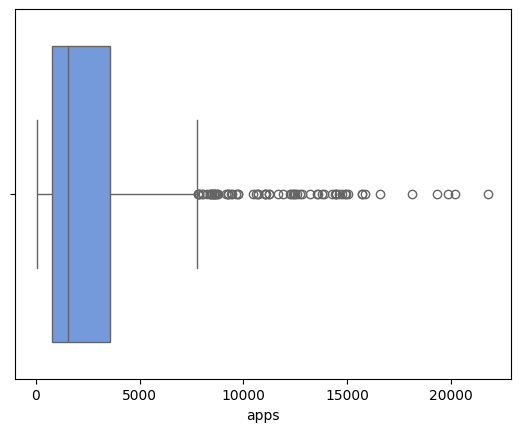

In [80]:
sns.boxplot(x = df['apps'], color = 'cornflowerblue');

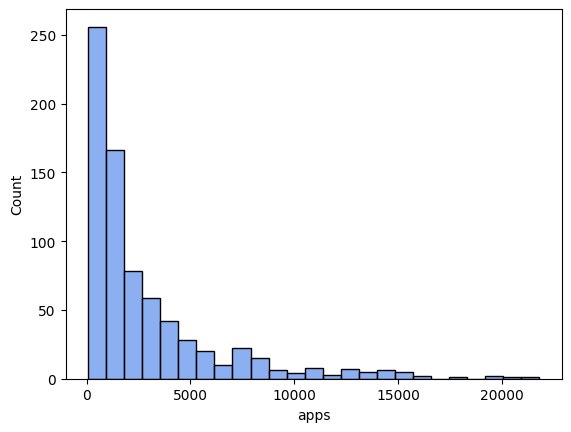

In [81]:
sns.histplot(df['apps'], bins = 25, color = 'cornflowerblue', edgecolor = 'black');

In [82]:
df.shape

(747, 19)

In [83]:
df[df['apps'] > 30000]

,university,private,apps,accept,enroll,top10perc,top25perc,f_undergrad,p_undergrad,outstate,room_board,books,personal,phd,terminal,s_f_ratio,perc_alumni,expend,grad_rate


In [84]:
# We can make a decision to drop the outlier, if we choose!

df = df[df['apps'] < 30000]
df.shape

(747, 19)

# EDA: Create Histograms of All Numerical Columns
---

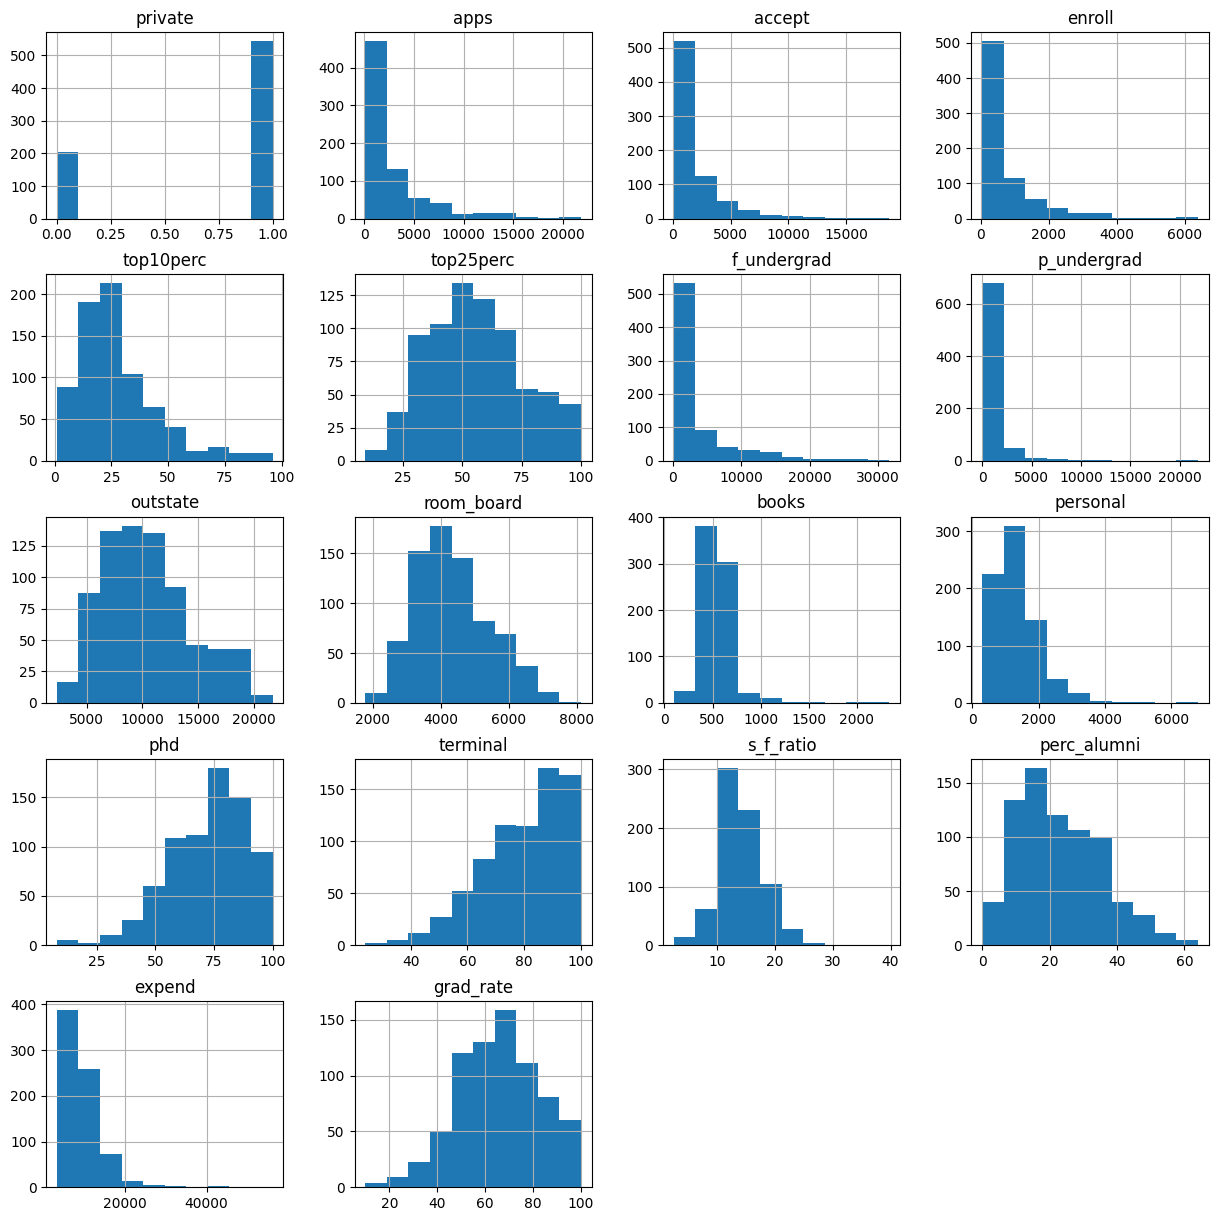

In [85]:
df.hist(figsize=(15, 15));

# EDA: Plot a Heatmap of the Correlation Matrix
---

Heatmaps are an effective way to visually examine the correlational structure of your predictors.

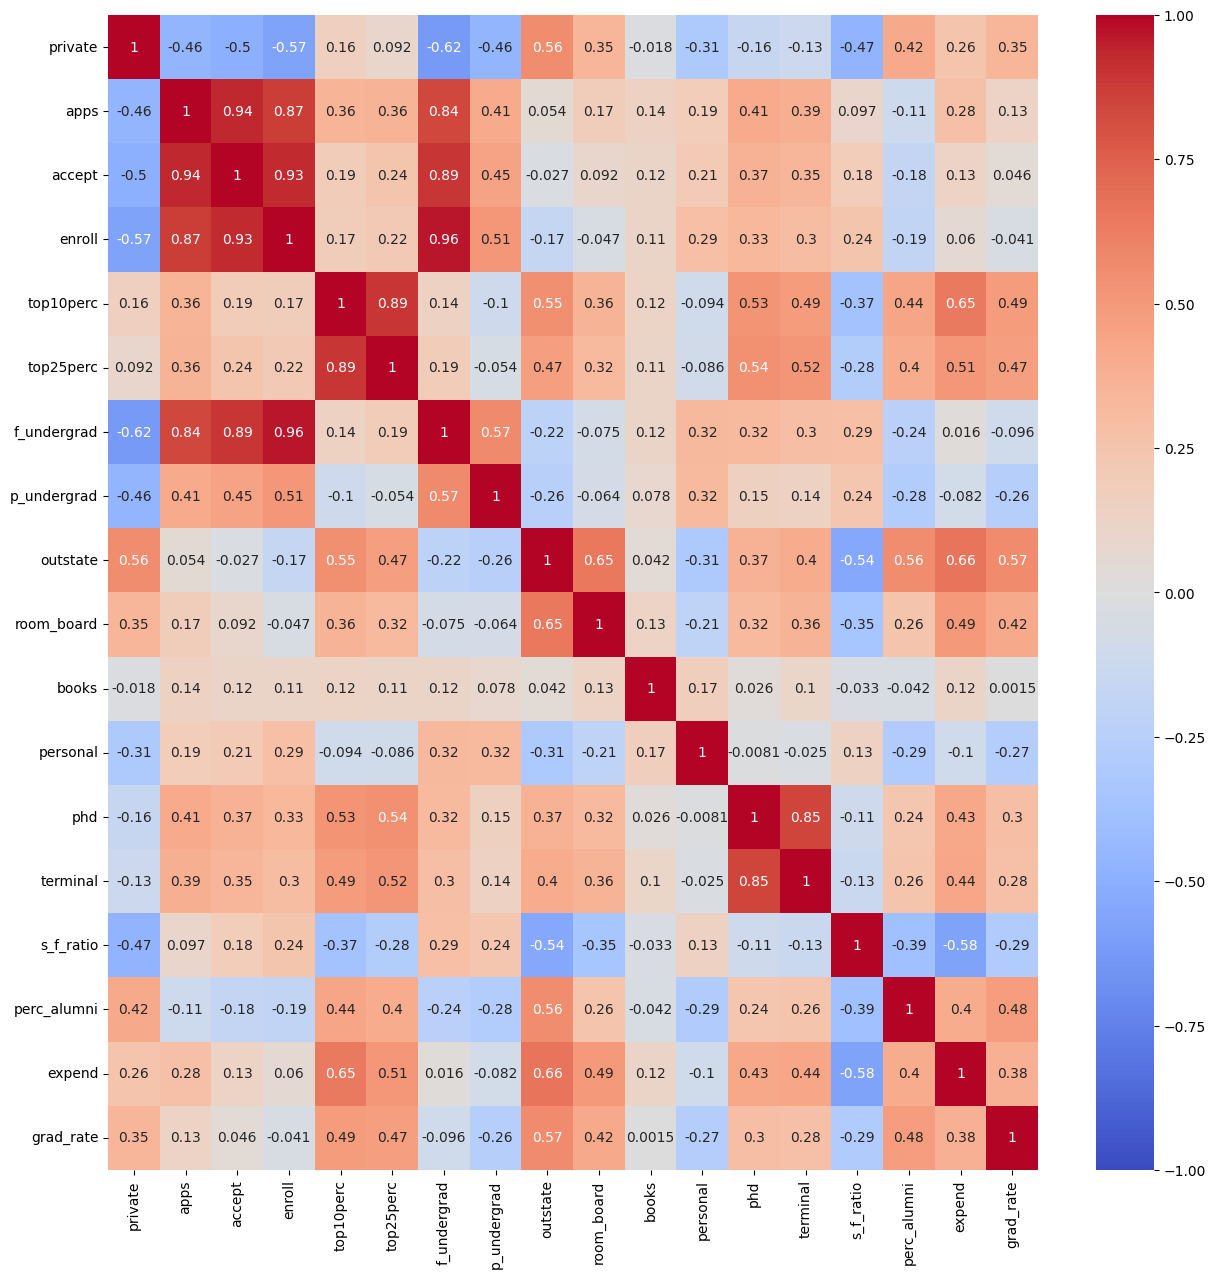

In [112]:
plt.figure(figsize=(15,15))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
           vmin = -1,
           vmax = 1,
           cmap = 'coolwarm');

##### What if I just wanted to look at the correlation to `apps`?

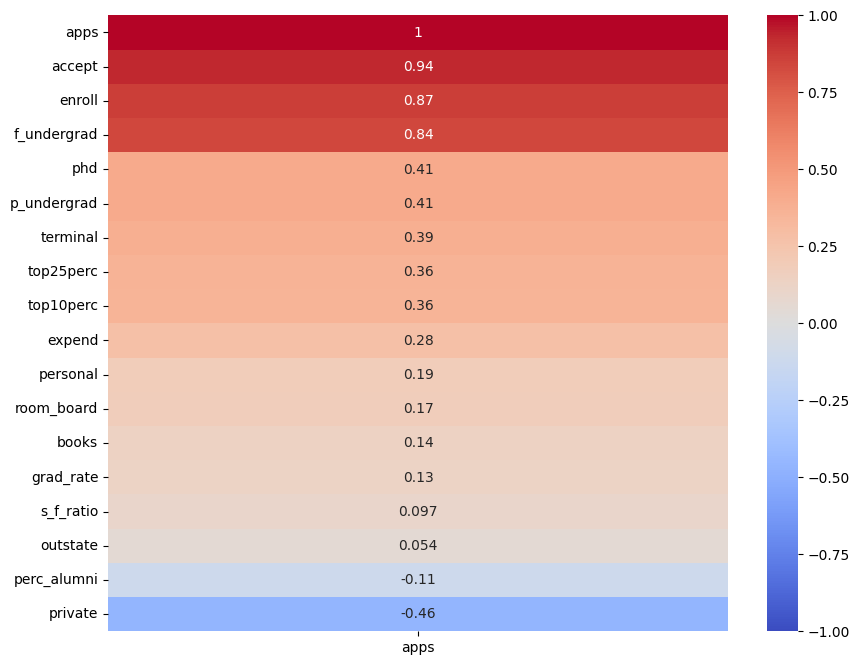

In [87]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True)[['apps']].sort_values(by='apps', ascending=False),
            annot=True,
           vmin=-1,
           vmax=1,
           cmap = 'coolwarm');

# EDA: Use seaborn's `.pairplot()` method to create scatterplots
---

Let's create a pairplot to see how some of our stronger predictors correlate to our target (`apps`). Instead of creating a pairplot of the entire DataFrame, we can use the `y_vars` and `x_vars` params to get a smaller subset.

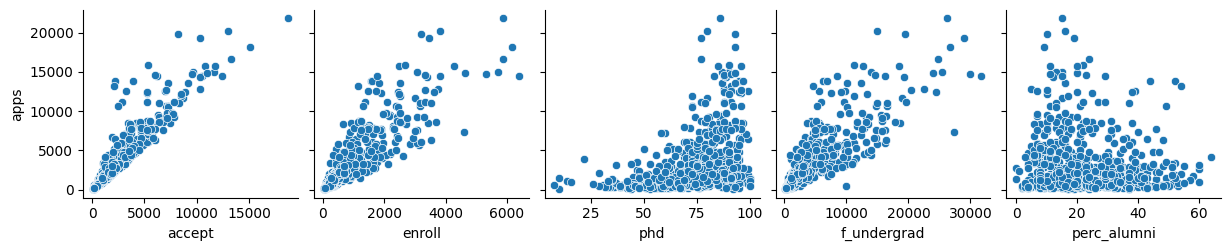

In [88]:
sns.pairplot(df, x_vars=['accept', 'enroll', 'phd', 'f_undergrad', 'perc_alumni'], y_vars=['apps']);

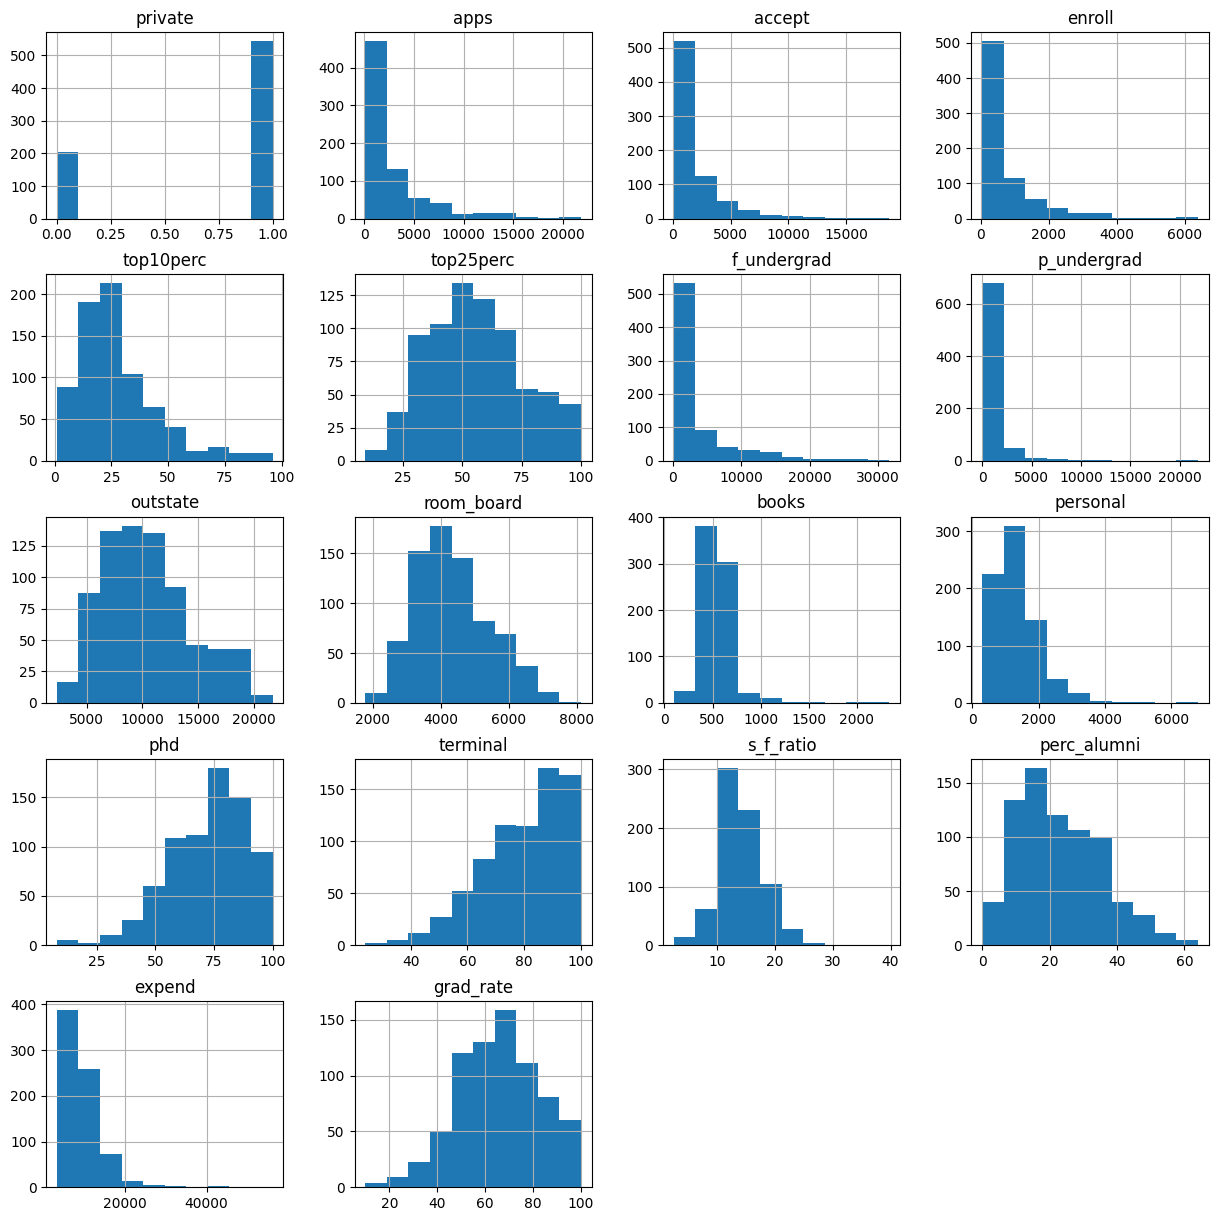

In [89]:
df.hist(figsize=(15, 15));

# Model Prep: Create our features matrix (`X`) and target vector (`y`)
---

What should our features be?

The `apps` column is our label: the number of applications received by that university.

In the cell below, create your `X` and `y` variables.

In [90]:
X = df.drop(columns=['university', 'accept', 'enroll', 'apps'])
y = df['apps']

# Model Prep: Train/test split
---

We always want to have a holdout set to test our model. Use the `train_test_split` function to split our `X` and `y` variables into a training set and a holdout set.

In [91]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Model Prep: Scaling
---

In the cell below, fit a `StandardScaler` to `X_train` and use it to transform both `X_train` and `X_test`. This is especially important when we learn about `Ridge` and `Lasso` next week!

In [92]:
ss = StandardScaler()

X_train = ss.fit_transform(X_train)
X_test = ss.transform(X_test)

# Model Prep: Instantiate our model
---


In [93]:
lr = LinearRegression()

# Evaluation
---

Use `.score` to evaluate the model.

In [94]:
lr.fit(X_train, y_train)

print(f"Training R2 = {lr.score(X_train, y_train)}")
print(f"Testing R2 = {lr.score(X_test, y_test)}")

Training R2 = 0.8269793960769836
Testing R2 = 0.7915343092045559


# LINE Assumptions
---


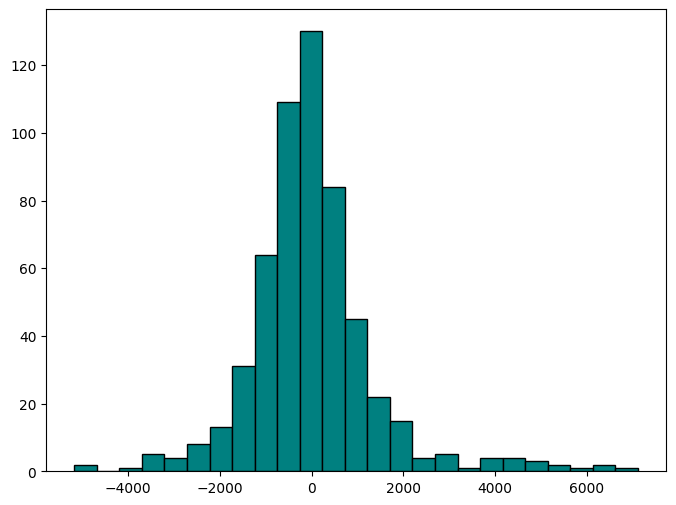

In [95]:
# N - Normality of errors
y_pred = lr.predict(X_train)
resids = y_train - y_pred

plt.figure(figsize = (8, 6))
plt.hist(resids, bins = 25, color = 'teal', edgecolor = 'black');

# Fine

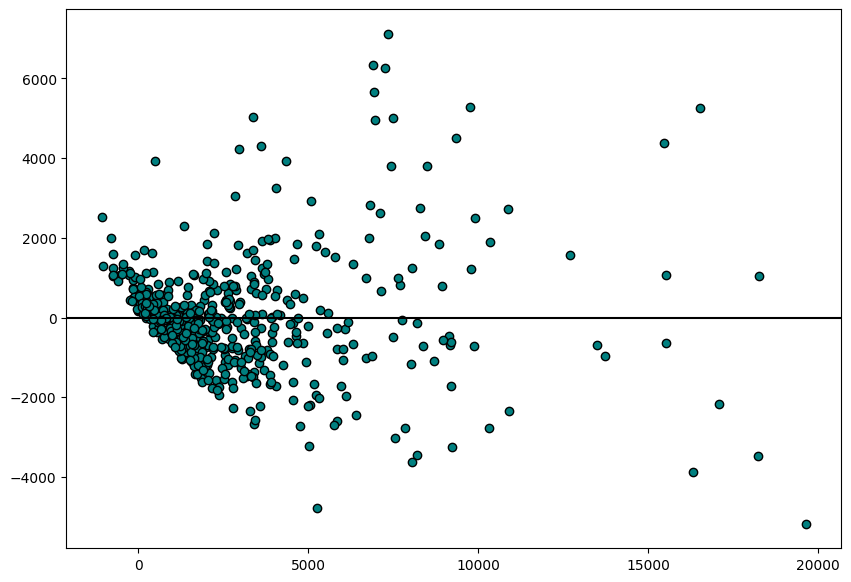

In [96]:
# E - Equal variance of errors
# Residual plot
plt.figure(figsize = (10, 7))
plt.scatter(y_pred, resids, color = 'teal', edgecolor = 'black')
plt.axhline(0, color = 'black');

# Heteroscedasticity (!!)

> Variance of the dependent variable varies and is not constant across the entire dataset.

In [97]:
 # What do we do? One option is to transform our dependent variable. A common transformation is to simply take the log of the dependent variable.

In [98]:
X = df.drop(columns=['university', 'accept', 'enroll', 'apps'])
y_log = np.log(df['apps'])

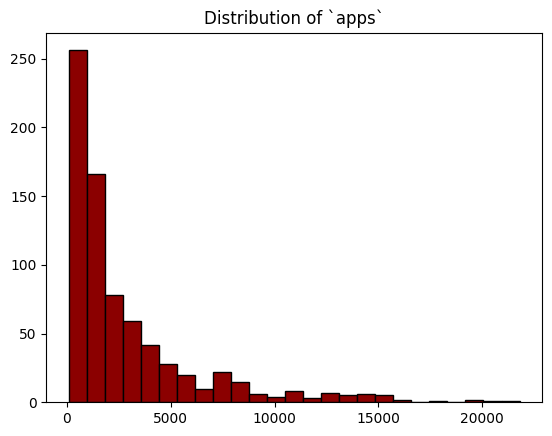

In [99]:
# What did this just do?
plt.hist(y, bins = 25, color = 'darkred', edgecolor = 'black')
plt.title('Distribution of `apps`');

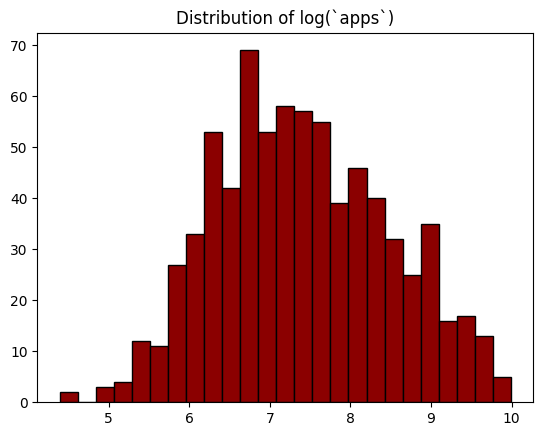

In [100]:
plt.hist(y_log, bins = 25, color = 'darkred', edgecolor = 'black')
plt.title('Distribution of log(`apps`)');

## **Note**
> Logarithmic transformation is a convenient means of transforming a highly skewed variable into a more normalized dataset.

In [101]:
X_train, X_test, y_train, y_test = train_test_split(X, y_log, random_state = 42)

In [102]:
ss = StandardScaler()

X_train = ss.fit_transform(X_train)
X_test = ss.transform(X_test)

In [103]:
lr_log = LinearRegression()
lr_log.fit(X_train, y_train)

LinearRegression()

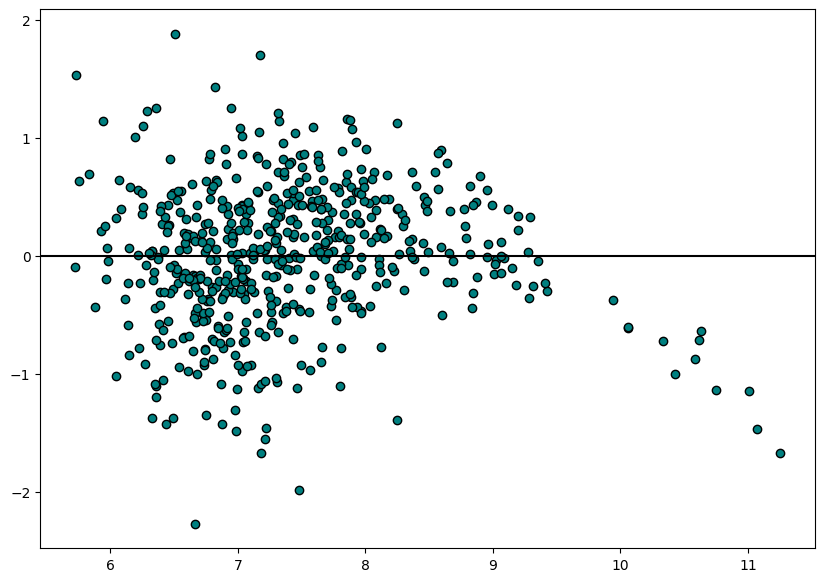

In [104]:
y_pred = lr_log.predict(X_train)
resids = y_train - y_pred

# E - Equal variance of errors
# Residual plot
plt.figure(figsize = (10, 7))
plt.scatter(y_pred, resids, color = 'teal', edgecolor = 'black')
plt.axhline(0, color = 'black');

In [105]:
lr_log.score(X_train, y_train)

0.6990084361813378

In [106]:
lr_log.score(X_test, y_test)

0.7716196960021482

### 😔

## Let's say that this model DID actually perform better... what do I need to remember to do to make predictions?

In [107]:
# You must use the exponential to "undo" our log transformation!
log_preds = lr_log.predict(X_train)
preds = np.exp(log_preds)

In [108]:
preds

array([ 2049.53794454,  1534.81754233,  1101.23694415,  8320.73446155,
        1368.02438529,   465.85428708,  1479.44790501, 46700.55996558,
        1978.78286733,   469.95810122,   665.42756975,   392.78688007,
         898.62993772,   926.13847186,  1233.28193304,  1804.3301388 ,
        2766.32231016,   858.70140417,  1167.61936397,   824.00343045,
         789.98792511,   308.77070101,  2934.81063486,  1770.05404181,
        1167.97149517,  3117.31604135,  1509.51078087,   560.52553757,
        2411.37355488,   774.23976612,  2674.23679139,   890.06174693,
        3249.99781411,   926.01328883,   673.9247783 ,  2094.75298045,
        1012.29523052,   692.58911987,   836.61412972,  2589.86781226,
        1084.30992608,  3582.8419421 ,  1976.8296767 ,  2172.19772352,
        2873.91322966,  7126.87685558,   597.06365449,  6586.13608876,
        3187.31113209,  1528.19802104,   863.01424378,   974.98115203,
        3739.39197998,  1279.17040367,  3102.53117388,  1690.896073  ,
      